In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Pneumonia Diagnosis Detection and Localization

This project develops a custom convolutional neural network (CNN) for binary classification of chest X-ray images into Normal and Lung Opacity classes. The model is trained entirely from scratch without using any pretrained model or transfer learning.

Grad-CAM is used for weakly supervised localization of lung opacity regions. The generated localization maps are converted into bounding boxes and evaluated against the ground-truth RSNA annotations using Intersection over Union (IoU).

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import pydicom

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("All imports successful!")

All imports successful!


In [4]:
DATA_DIR = "/kaggle/input/competitions/rsna-pneumonia-detection-challenge"

IMAGE_DIR = DATA_DIR + "/stage_2_train_images"

print("Dataset contents:")
print(os.listdir(DATA_DIR))

Dataset contents:
['stage_2_train_images', 'stage_2_sample_submission.csv', 'stage_2_detailed_class_info.csv', 'GCP Credits Request Link - RSNA.txt', 'stage_2_train_labels.csv', 'stage_2_test_images']


In [5]:
labels = pd.read_csv(DATA_DIR + "/stage_2_train_labels.csv")
class_info = pd.read_csv(DATA_DIR + "/stage_2_detailed_class_info.csv")

print("Labels shape:", labels.shape)
print("Class info shape:", class_info.shape)

print("\nClass distribution:")
print(class_info["class"].value_counts())

Labels shape: (30227, 6)
Class info shape: (30227, 2)

Class distribution:
class
No Lung Opacity / Not Normal    11821
Lung Opacity                     9555
Normal                           8851
Name: count, dtype: int64


## Dataset Preparation

The project uses the RSNA Pneumonia Detection Challenge dataset.

For this project:
- 1,000 Normal images were selected.
- 1,000 Lung Opacity images were selected.
- Total dataset size: 2,000 images.
- 1,400 images were used for training.
- 300 images were used for validation.
- 300 images were used for testing.

The No Lung Opacity / Not Normal category was excluded because the project focuses on binary classification between Normal and Lung Opacity.

## Custom CNN

A custom convolutional neural network was designed and trained entirely from scratch. No pretrained model, ImageNet weights, or transfer learning was used.

The network consists of four convolutional blocks followed by global average pooling, dropout, and a fully connected classification layer.

In [6]:
binary_df = class_info[
    class_info["class"].isin(["Normal", "Lung Opacity"])
].copy()

binary_df["label"] = (
    binary_df["class"] == "Lung Opacity"
).astype(int)

print(binary_df["class"].value_counts())

class
Lung Opacity    9555
Normal          8851
Name: count, dtype: int64


In [7]:
binary_unique_df = binary_df.drop_duplicates(
    subset="patientId"
).copy()

print("Unique images:", len(binary_unique_df))
print(binary_unique_df["class"].value_counts())

Unique images: 14863
class
Normal          8851
Lung Opacity    6012
Name: count, dtype: int64


In [9]:
normal_df = binary_unique_df[
    binary_unique_df["label"] == 0
].sample(n=1000, random_state=42)

opacity_df = binary_unique_df[
    binary_unique_df["label"] == 1
].sample(n=1000, random_state=42)

In [10]:
project_df = pd.concat([
    normal_df,
    opacity_df
]).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Total images:", len(project_df))
print("\nClass counts:")
print(project_df["label"].value_counts())

Total images: 2000

Class counts:
label
1    1000
0    1000
Name: count, dtype: int64


In [11]:
train_df, temp_df = train_test_split(
    project_df,
    test_size=0.30,
    stratify=project_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Temporary:", len(temp_df))

Training: 1400
Temporary: 600


In [12]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 1400
Validation: 300
Test: 300


In [13]:
print("Training classes:")
print(train_df["label"].value_counts())

print("\nValidation classes:")
print(val_df["label"].value_counts())

print("\nTest classes:")
print(test_df["label"].value_counts())

Training classes:
label
0    700
1    700
Name: count, dtype: int64

Validation classes:
label
1    150
0    150
Name: count, dtype: int64

Test classes:
label
1    150
0    150
Name: count, dtype: int64


In [14]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("Transforms created!")

Transforms created!


In [16]:
class PneumoniaDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        patient_id = row["patientId"]
        label = int(row["label"])

        image_path = os.path.join(
            self.image_dir,
            patient_id + ".dcm"
        )

        dicom = pydicom.dcmread(image_path)
        image = dicom.pixel_array.astype(np.float32)

        # Normalize pixel values to 0-255
        image = image - image.min()

        if image.max() > 0:
            image = image / image.max() * 255.0

        image = image.astype(np.uint8)

        # Convert grayscale X-ray to RGB
        image = Image.fromarray(image).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [17]:
train_dataset = PneumoniaDataset(
    train_df,
    IMAGE_DIR,
    train_transform
)

val_dataset = PneumoniaDataset(
    val_df,
    IMAGE_DIR,
    test_transform
)

test_dataset = PneumoniaDataset(
    test_df,
    IMAGE_DIR,
    test_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 1400
Validation: 300
Test: 300


In [19]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created!
Training batches: 44
Validation batches: 10
Test batches: 10


In [20]:
images, labels_batch = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)
print("Labels:", labels_batch[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([0, 0, 1, 1, 0, 0, 1, 0, 1, 0])


## Custom CNN Architecture

A custom convolutional neural network was designed and trained entirely from scratch. No pretrained model, ImageNet weights, or transfer learning was used.

The network consists of four convolutional layers followed by global average pooling, dropout, and a fully connected classification layer.

In [22]:
class CustomCNN(nn.Module):

    def __init__(self):
        super(CustomCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(256, 2)

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.pool(self.relu(self.conv4(x)))

        x = self.global_pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

In [23]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CustomCNN().to(device)

print("Device:", device)
print(model)

Device: cuda
CustomCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)


In [24]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 388930
Trainable parameters: 388930


## Model Training

The custom CNN was trained from scratch using the Adam optimizer and cross-entropy loss. The model was trained for 5 epochs using the training set, while the validation set was used to monitor performance during training.

In [25]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer ready!")

Loss function and optimizer ready!


In [27]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [28]:
def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [29]:
EPOCHS = 5

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

Epoch 1/5 | Train Loss: 0.6867 | Train Acc: 56.14% | Val Loss: 0.6432 | Val Acc: 69.33%
Epoch 2/5 | Train Loss: 0.6666 | Train Acc: 63.57% | Val Loss: 0.6146 | Val Acc: 72.33%
Epoch 3/5 | Train Loss: 0.6434 | Train Acc: 67.43% | Val Loss: 0.6210 | Val Acc: 73.00%
Epoch 4/5 | Train Loss: 0.6069 | Train Acc: 71.50% | Val Loss: 0.5637 | Val Acc: 79.67%
Epoch 5/5 | Train Loss: 0.5861 | Train Acc: 73.43% | Val Loss: 0.5620 | Val Acc: 78.67%


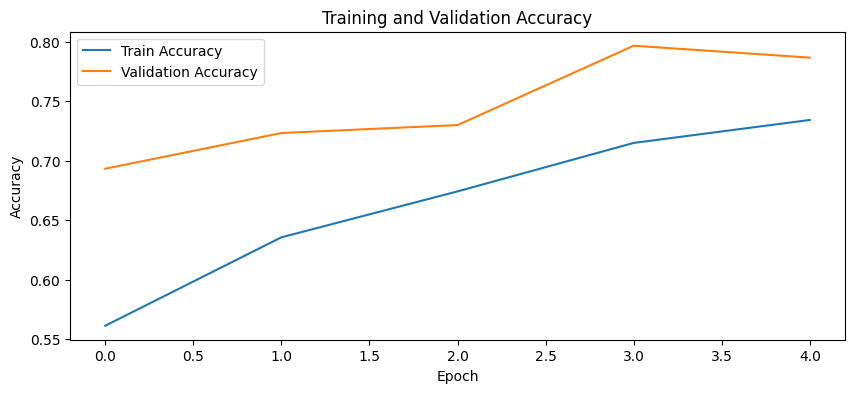

In [30]:
plt.figure(figsize=(10, 4))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [31]:
def evaluate_model(model, loader, device):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)
            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(
                probabilities[:, 1].cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )


y_true, y_pred, y_prob = evaluate_model(
    model,
    test_loader,
    device
)

print("Test evaluation complete!")

Test evaluation complete!


## Classification Results

The trained custom CNN was evaluated on the unseen test set using accuracy, precision, recall, F1-score, and ROC-AUC. A confusion matrix was also used to analyze the classification performance.

In [32]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

Accuracy : 0.7867
Precision: 0.7688
Recall   : 0.8200
F1 Score : 0.7935
ROC-AUC  : 0.8207


Confusion Matrix:
[[113  37]
 [ 27 123]]


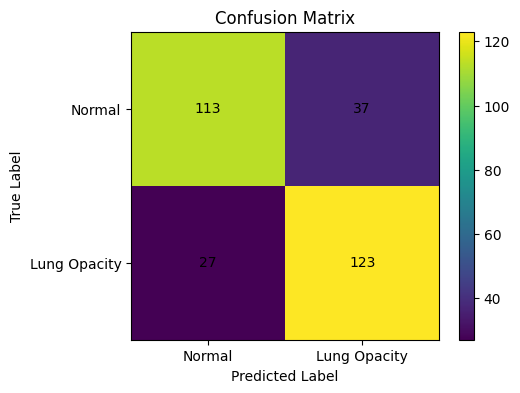

In [33]:
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], ["Normal", "Lung Opacity"])
plt.yticks([0, 1], ["Normal", "Lung Opacity"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.colorbar()
plt.show()

## Grad-CAM Localization

Grad-CAM was applied to the final convolutional layer of the custom CNN to generate class-discriminative heatmaps. The heatmaps were thresholded to obtain predicted bounding boxes for Lung Opacity regions.

In [35]:
class GradCAM:

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.target_layer.register_forward_hook(
            self.save_activation
        )

        self.target_layer.register_full_backward_hook(
            self.save_gradient
        )

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, image):

        self.model.eval()

        self.model.zero_grad()

        output = self.model(image)

        predicted_class = torch.argmax(output, dim=1).item()

        score = output[:, predicted_class]

        score.backward()

        gradients = self.gradients
        activations = self.activations

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (weights * activations).sum(dim=1)

        cam = torch.relu(cam)

        cam = cam.squeeze().detach().cpu().numpy()

        cam = cv2.resize(cam, (224, 224))

        if cam.max() > 0:
            cam = cam / cam.max()

        return cam, predicted_class

In [36]:
gradcam = GradCAM(
    model,
    model.conv4
)

print("Grad-CAM ready!")

Grad-CAM ready!


In [37]:
# Find a Lung Opacity image from the test set
opacity_test = test_df[test_df["label"] == 1].iloc[0]

print("Patient ID:", opacity_test["patientId"])
print("Class:", opacity_test["class"])

Patient ID: d9728525-2c4b-4526-bbf7-873831872a20
Class: Lung Opacity


In [38]:
# Get the image from our test dataset
index = test_df.index[
    test_df["patientId"] == opacity_test["patientId"]
][0]

image_tensor, true_label = test_dataset[
    test_df.index.get_loc(index)
]

# Add batch dimension and move to GPU
input_image = image_tensor.unsqueeze(0).to(device)

# Generate Grad-CAM
cam, predicted_class = gradcam.generate(input_image)

print("True class:", "Lung Opacity" if true_label == 1 else "Normal")
print("Predicted class:",
      "Lung Opacity" if predicted_class == 1 else "Normal")
print("CAM shape:", cam.shape)

True class: Lung Opacity
Predicted class: Lung Opacity
CAM shape: (224, 224)


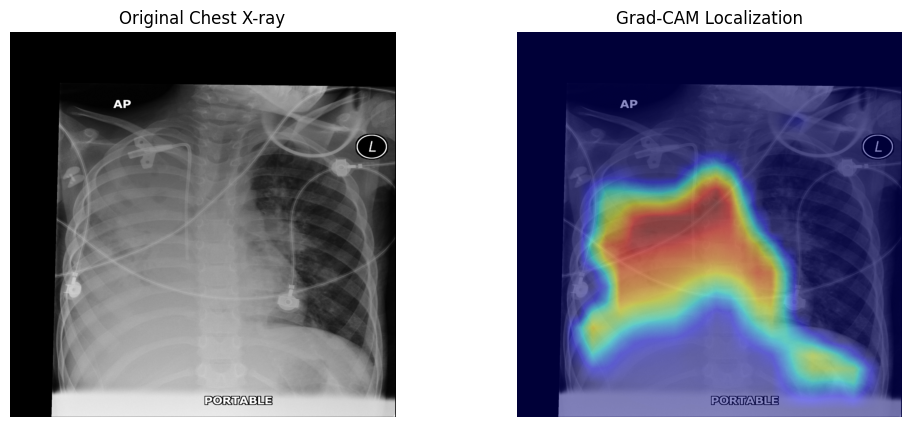

In [39]:
# Read the original DICOM image
dicom = pydicom.dcmread(
    os.path.join(
        IMAGE_DIR,
        opacity_test["patientId"] + ".dcm"
    )
)

original_image = dicom.pixel_array.astype(np.float32)

# Normalize for display
original_image = (
    original_image - original_image.min()
)

if original_image.max() > 0:
    original_image = (
        original_image / original_image.max()
    )

# Resize CAM to original image size
cam_original = cv2.resize(
    cam,
    (original_image.shape[1], original_image.shape[0])
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image, cmap="gray")
plt.imshow(
    cam_original,
    cmap="jet",
    alpha=0.45
)
plt.title("Grad-CAM Localization")
plt.axis("off")

plt.show()

In [40]:
# Threshold the Grad-CAM
threshold = 0.5

binary_mask = (cam_original >= threshold).astype(np.uint8) * 255

# Find connected regions
contours, _ = cv2.findContours(
    binary_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Find the largest region
if len(contours) > 0:

    largest_contour = max(contours, key=cv2.contourArea)

    x, y, w, h = cv2.boundingRect(largest_contour)

    print("Predicted bounding box:")
    print("x =", x, "y =", y, "width =", w, "height =", h)

else:

    x, y, w, h = None, None, None, None
    print("No bounding box detected.")

Predicted bounding box:
x = 185 y = 370 width = 518 height = 461


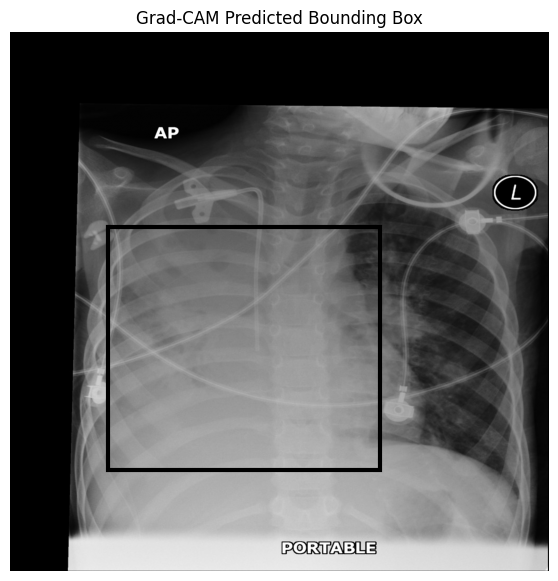

In [41]:
plt.figure(figsize=(7, 7))

plt.imshow(original_image, cmap="gray")

if x is not None:

    rectangle = plt.Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        linewidth=3
    )

    plt.gca().add_patch(rectangle)

plt.title("Grad-CAM Predicted Bounding Box")
plt.axis("off")
plt.show()

In [43]:
# Get all ground-truth annotations for this patient
gt_boxes = labels[
    labels["patientId"] == opacity_test["patientId"]
].copy()

# Keep only valid bounding-box annotations
gt_boxes = gt_boxes.dropna(
    subset=["x", "y", "width", "height"]
)

print(gt_boxes[[
    "x", "y", "width", "height"
]])

           x      y  width  height
24190  227.0  474.0  250.0   200.0


In [44]:
if len(gt_boxes) > 0:

    gt_x1 = gt_boxes["x"].min()
    gt_y1 = gt_boxes["y"].min()

    gt_x2 = (
        gt_boxes["x"] +
        gt_boxes["width"]
    ).max()

    gt_y2 = (
        gt_boxes["y"] +
        gt_boxes["height"]
    ).max()

    print("Ground-truth bounding box:")
    print(
        "x1 =", gt_x1,
        "y1 =", gt_y1,
        "x2 =", gt_x2,
        "y2 =", gt_y2
    )

else:
    print("No ground-truth bounding box found.")

Ground-truth bounding box:
x1 = 227.0 y1 = 474.0 x2 = 477.0 y2 = 674.0


## IoU Evaluation

The predicted Grad-CAM bounding boxes were compared with the ground-truth bounding boxes provided by the RSNA dataset.

Intersection over Union (IoU) was used to measure the overlap between the predicted and ground-truth regions.

In [45]:
# Predicted box coordinates
pred_x1 = x
pred_y1 = y
pred_x2 = x + w
pred_y2 = y + h

# Intersection
inter_x1 = max(pred_x1, gt_x1)
inter_y1 = max(pred_y1, gt_y1)
inter_x2 = min(pred_x2, gt_x2)
inter_y2 = min(pred_y2, gt_y2)

inter_width = max(0, inter_x2 - inter_x1)
inter_height = max(0, inter_y2 - inter_y1)

intersection = inter_width * inter_height

# Areas
pred_area = w * h

gt_area = (
    (gt_x2 - gt_x1) *
    (gt_y2 - gt_y1)
)

# IoU
union = pred_area + gt_area - intersection

iou = intersection / union if union > 0 else 0

print(f"IoU: {iou:.4f}")

IoU: 0.2094


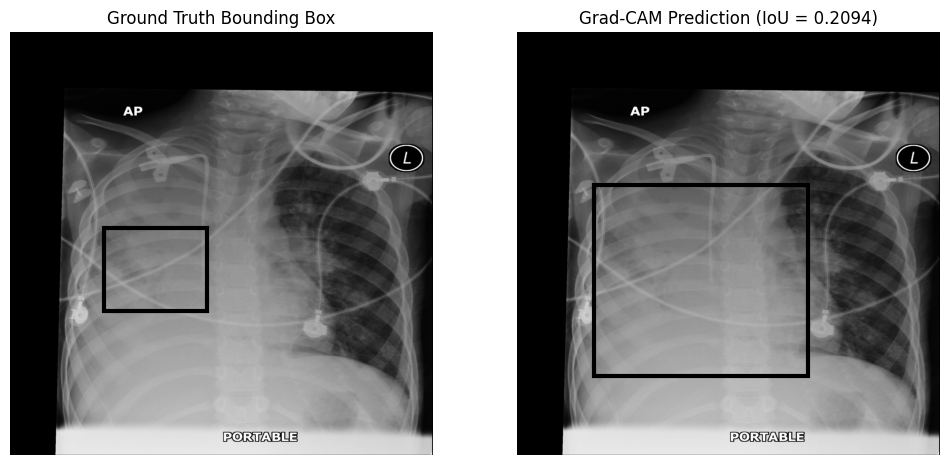

In [46]:
plt.figure(figsize=(12, 6))

# Ground truth
plt.subplot(1, 2, 1)

plt.imshow(original_image, cmap="gray")

for _, row in gt_boxes.iterrows():
    rect = plt.Rectangle(
        (row["x"], row["y"]),
        row["width"],
        row["height"],
        fill=False,
        linewidth=3
    )
    plt.gca().add_patch(rect)

plt.title("Ground Truth Bounding Box")
plt.axis("off")


# Grad-CAM prediction
plt.subplot(1, 2, 2)

plt.imshow(original_image, cmap="gray")

rect = plt.Rectangle(
    (x, y),
    w,
    h,
    fill=False,
    linewidth=3
)

plt.gca().add_patch(rect)

plt.title(f"Grad-CAM Prediction (IoU = {iou:.4f})")
plt.axis("off")

plt.show()

In [48]:
def calculate_iou(pred_box, gt_boxes):

    if pred_box is None or len(gt_boxes) == 0:
        return 0.0

    px1, py1, px2, py2 = pred_box

    gt_x1 = gt_boxes["x"].min()
    gt_y1 = gt_boxes["y"].min()

    gt_x2 = (
        gt_boxes["x"] +
        gt_boxes["width"]
    ).max()

    gt_y2 = (
        gt_boxes["y"] +
        gt_boxes["height"]
    ).max()

    # Intersection
    ix1 = max(px1, gt_x1)
    iy1 = max(py1, gt_y1)
    ix2 = min(px2, gt_x2)
    iy2 = min(py2, gt_y2)

    iw = max(0, ix2 - ix1)
    ih = max(0, iy2 - iy1)

    intersection = iw * ih

    # Areas
    pred_area = max(0, px2 - px1) * max(0, py2 - py1)
    gt_area = max(0, gt_x2 - gt_x1) * max(0, gt_y2 - gt_y1)

    union = pred_area + gt_area - intersection

    return intersection / union if union > 0 else 0.0

In [49]:
# Select 20 Lung Opacity cases from the test set
localization_df = test_df[
    test_df["label"] == 1
].sample(
    n=20,
    random_state=42
).reset_index(drop=True)

localization_results = []

for i, row in localization_df.iterrows():

    patient_id = row["patientId"]

    try:

        # Load DICOM
        dicom = pydicom.dcmread(
            os.path.join(
                IMAGE_DIR,
                patient_id + ".dcm"
            )
        )

        original_image = dicom.pixel_array.astype(np.float32)

        # Normalize image
        image = original_image - original_image.min()

        if image.max() > 0:
            image = image / image.max() * 255.0

        image = image.astype(np.uint8)

        # Convert to RGB and apply test transform
        pil_image = Image.fromarray(image).convert("RGB")
        input_tensor = test_transform(pil_image)
        input_tensor = input_tensor.unsqueeze(0).to(device)

        # Generate Grad-CAM
        cam, predicted_class = gradcam.generate(input_tensor)

        # Resize CAM to original image dimensions
        cam_original = cv2.resize(
            cam,
            (original_image.shape[1], original_image.shape[0])
        )

        # Threshold
        threshold = 0.5

        binary_mask = (
            cam_original >= threshold
        ).astype(np.uint8) * 255

        # Find contours
        contours, _ = cv2.findContours(
            binary_mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        # Predicted bounding box
        if len(contours) > 0:

            largest_contour = max(
                contours,
                key=cv2.contourArea
            )

            x1, y1, w1, h1 = cv2.boundingRect(
                largest_contour
            )

            pred_box = (
                x1,
                y1,
                x1 + w1,
                y1 + h1
            )

        else:
            pred_box = None

        # Ground-truth boxes
        gt_boxes = labels[
            labels["patientId"] == patient_id
        ].dropna(
            subset=["x", "y", "width", "height"]
        )

        # IoU
        iou_value = calculate_iou(
            pred_box,
            gt_boxes
        )

        localization_results.append({
            "patientId": patient_id,
            "predicted_class": predicted_class,
            "iou": iou_value
        })

        print(
            f"{i+1:02d}/20 | "
            f"{patient_id} | "
            f"Predicted: {predicted_class} | "
            f"IoU: {iou_value:.4f}"
        )

    except Exception as e:

        print(
            f"{i+1:02d}/20 | "
            f"{patient_id} | ERROR: {e}"
        )

01/20 | bebdcf14-c068-400b-b006-9d4169e18fb1 | Predicted: 0 | IoU: 0.0294
02/20 | b0052168-b95f-477b-9220-e26a6d33f1d0 | Predicted: 0 | IoU: 0.0000
03/20 | 0d9b1283-fc24-4fd3-a520-bc5d563e13e1 | Predicted: 1 | IoU: 0.0181
04/20 | 6fd0d3d2-a990-41a8-b843-94d2356afe42 | Predicted: 1 | IoU: 0.4103
05/20 | 47cb63e4-4f88-40b7-b4d8-725fdc053c28 | Predicted: 1 | IoU: 0.0614
06/20 | ed0c5d1e-934a-4e31-9221-3a6a69ec9c1b | Predicted: 0 | IoU: 0.0000
07/20 | 8c5f7cb0-f287-4221-8e6f-12ec2daa2ae0 | Predicted: 1 | IoU: 0.4869
08/20 | 79255e97-c107-47ee-918c-6eba3081f3bc | Predicted: 1 | IoU: 0.0190
09/20 | 3cc57eeb-c3e0-407d-834f-2a1f417d157a | Predicted: 1 | IoU: 0.3698
10/20 | d7131b83-ef4c-4a0a-b1a2-d09c163bda48 | Predicted: 1 | IoU: 0.0289
11/20 | ba8d3130-4063-4339-bbfa-474259060f5b | Predicted: 1 | IoU: 0.1213
12/20 | 8fefb690-a1b7-4948-98a6-088e5dd8b3da | Predicted: 0 | IoU: 0.0000
13/20 | b5df5721-d026-4638-8b8d-67260798f6a7 | Predicted: 1 | IoU: 0.2121
14/20 | 00a05408-8291-4231-886e-13763e

In [51]:
# Select 20 Lung Opacity cases from the test set
localization_df = test_df[
    test_df["label"] == 1
].sample(
    n=20,
    random_state=42
).reset_index(drop=True)

localization_results = []

for i, row in localization_df.iterrows():

    patient_id = row["patientId"]

    try:

        # Load DICOM
        dicom = pydicom.dcmread(
            os.path.join(
                IMAGE_DIR,
                patient_id + ".dcm"
            )
        )

        original_image = dicom.pixel_array.astype(np.float32)

        # Normalize image
        image = original_image - original_image.min()

        if image.max() > 0:
            image = image / image.max() * 255.0

        image = image.astype(np.uint8)

        # Convert to RGB and apply test transform
        pil_image = Image.fromarray(image).convert("RGB")
        input_tensor = test_transform(pil_image)
        input_tensor = input_tensor.unsqueeze(0).to(device)

        # Generate Grad-CAM
        cam, predicted_class = gradcam.generate(input_tensor)

        # Resize CAM to original image dimensions
        cam_original = cv2.resize(
            cam,
            (original_image.shape[1], original_image.shape[0])
        )

        # Threshold
        threshold = 0.5

        binary_mask = (
            cam_original >= threshold
        ).astype(np.uint8) * 255

        # Find contours
        contours, _ = cv2.findContours(
            binary_mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        # Predicted bounding box
        if len(contours) > 0:

            largest_contour = max(
                contours,
                key=cv2.contourArea
            )

            x1, y1, w1, h1 = cv2.boundingRect(
                largest_contour
            )

            pred_box = (
                x1,
                y1,
                x1 + w1,
                y1 + h1
            )

        else:
            pred_box = None

        # Ground-truth boxes
        gt_boxes = labels[
            labels["patientId"] == patient_id
        ].dropna(
            subset=["x", "y", "width", "height"]
        )

        # IoU
        iou_value = calculate_iou(
            pred_box,
            gt_boxes
        )

        localization_results.append({
            "patientId": patient_id,
            "predicted_class": predicted_class,
            "iou": iou_value
        })

        print(
            f"{i+1:02d}/20 | "
            f"{patient_id} | "
            f"Predicted: {predicted_class} | "
            f"IoU: {iou_value:.4f}"
        )

    except Exception as e:

        print(
            f"{i+1:02d}/20 | "
            f"{patient_id} | ERROR: {e}"
        )

01/20 | bebdcf14-c068-400b-b006-9d4169e18fb1 | Predicted: 0 | IoU: 0.0294
02/20 | b0052168-b95f-477b-9220-e26a6d33f1d0 | Predicted: 0 | IoU: 0.0000
03/20 | 0d9b1283-fc24-4fd3-a520-bc5d563e13e1 | Predicted: 1 | IoU: 0.0181
04/20 | 6fd0d3d2-a990-41a8-b843-94d2356afe42 | Predicted: 1 | IoU: 0.4103
05/20 | 47cb63e4-4f88-40b7-b4d8-725fdc053c28 | Predicted: 1 | IoU: 0.0614
06/20 | ed0c5d1e-934a-4e31-9221-3a6a69ec9c1b | Predicted: 0 | IoU: 0.0000
07/20 | 8c5f7cb0-f287-4221-8e6f-12ec2daa2ae0 | Predicted: 1 | IoU: 0.4869
08/20 | 79255e97-c107-47ee-918c-6eba3081f3bc | Predicted: 1 | IoU: 0.0190
09/20 | 3cc57eeb-c3e0-407d-834f-2a1f417d157a | Predicted: 1 | IoU: 0.3698
10/20 | d7131b83-ef4c-4a0a-b1a2-d09c163bda48 | Predicted: 1 | IoU: 0.0289
11/20 | ba8d3130-4063-4339-bbfa-474259060f5b | Predicted: 1 | IoU: 0.1213
12/20 | 8fefb690-a1b7-4948-98a6-088e5dd8b3da | Predicted: 0 | IoU: 0.0000
13/20 | b5df5721-d026-4638-8b8d-67260798f6a7 | Predicted: 1 | IoU: 0.2121
14/20 | 00a05408-8291-4231-886e-13763e

In [52]:
results_df = pd.DataFrame(localization_results)

iou_values = results_df["iou"].values

print("\nLocalization Results")
print("--------------------")
print("Number of cases:", len(iou_values))
print(f"Mean IoU   : {np.mean(iou_values):.4f}")
print(f"Median IoU : {np.median(iou_values):.4f}")
print(f"Best IoU   : {np.max(iou_values):.4f}")
print(f"Worst IoU  : {np.min(iou_values):.4f}")

print("\nPer-case results:")
print(results_df)


Localization Results
--------------------
Number of cases: 20
Mean IoU   : 0.1409
Median IoU : 0.0492
Best IoU   : 0.4869
Worst IoU  : 0.0000

Per-case results:
                               patientId  predicted_class       iou
0   bebdcf14-c068-400b-b006-9d4169e18fb1                0  0.029431
1   b0052168-b95f-477b-9220-e26a6d33f1d0                0  0.000000
2   0d9b1283-fc24-4fd3-a520-bc5d563e13e1                1  0.018078
3   6fd0d3d2-a990-41a8-b843-94d2356afe42                1  0.410264
4   47cb63e4-4f88-40b7-b4d8-725fdc053c28                1  0.061400
5   ed0c5d1e-934a-4e31-9221-3a6a69ec9c1b                0  0.000000
6   8c5f7cb0-f287-4221-8e6f-12ec2daa2ae0                1  0.486872
7   79255e97-c107-47ee-918c-6eba3081f3bc                1  0.018969
8   3cc57eeb-c3e0-407d-834f-2a1f417d157a                1  0.369781
9   d7131b83-ef4c-4a0a-b1a2-d09c163bda48                1  0.028861
10  ba8d3130-4063-4339-bbfa-474259060f5b                1  0.121251
11  8fefb690-a1b7-4948

In [53]:
positive_results = results_df[
    results_df["predicted_class"] == 1
].copy()

print("Total localization cases:", len(results_df))
print("Predicted Lung Opacity:", len(positive_results))
print("Predicted Normal:", len(results_df) - len(positive_results))

print("\nIoU for predicted Lung Opacity cases:")
print(f"Mean IoU   : {positive_results['iou'].mean():.4f}")
print(f"Median IoU : {positive_results['iou'].median():.4f}")
print(f"Best IoU   : {positive_results['iou'].max():.4f}")
print(f"Worst IoU  : {positive_results['iou'].min():.4f}")

Total localization cases: 20
Predicted Lung Opacity: 16
Predicted Normal: 4

IoU for predicted Lung Opacity cases:
Mean IoU   : 0.1743
Median IoU : 0.0927
Best IoU   : 0.4869
Worst IoU  : 0.0000


In [54]:
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

Accuracy : 0.7867
Precision: 0.7688
Recall   : 0.8200
F1 Score : 0.7935
ROC-AUC  : 0.8207


## Grad-CAM Threshold Experiment

Different Grad-CAM thresholds were evaluated to determine their effect on localization performance.

The tested thresholds were 0.3, 0.4, 0.5, 0.6, and 0.7. The threshold producing the highest mean IoU was selected as the final threshold.

In [55]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:

    ious = []

    for _, row in localization_df.iterrows():

        patient_id = row["patientId"]

        try:
            # Load DICOM
            dicom = pydicom.dcmread(
                os.path.join(
                    IMAGE_DIR,
                    patient_id + ".dcm"
                )
            )

            original_image = dicom.pixel_array.astype(np.float32)

            # Normalize
            image = original_image - original_image.min()

            if image.max() > 0:
                image = image / image.max() * 255.0

            image = image.astype(np.uint8)

            # Prepare input
            pil_image = Image.fromarray(image).convert("RGB")
            input_tensor = test_transform(pil_image)
            input_tensor = input_tensor.unsqueeze(0).to(device)

            # Grad-CAM
            cam, predicted_class = gradcam.generate(
                input_tensor
            )

            # Only evaluate localization if model predicts Lung Opacity
            if predicted_class != 1:
                continue

            # Resize CAM
            cam_original = cv2.resize(
                cam,
                (original_image.shape[1],
                 original_image.shape[0])
            )

            # Threshold
            binary_mask = (
                cam_original >= threshold
            ).astype(np.uint8) * 255

            # Find contours
            contours, _ = cv2.findContours(
                binary_mask,
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )

            if len(contours) == 0:
                continue

            # Largest region
            largest_contour = max(
                contours,
                key=cv2.contourArea
            )

            x1, y1, w1, h1 = cv2.boundingRect(
                largest_contour
            )

            pred_box = (
                x1,
                y1,
                x1 + w1,
                y1 + h1
            )

            # Ground truth
            gt_boxes = labels[
                labels["patientId"] == patient_id
            ].dropna(
                subset=["x", "y", "width", "height"]
            )

            iou_value = calculate_iou(
                pred_box,
                gt_boxes
            )

            ious.append(iou_value)

        except Exception:
            continue

    if len(ious) > 0:
        threshold_results.append({
            "threshold": threshold,
            "cases": len(ious),
            "mean_iou": np.mean(ious),
            "median_iou": np.median(ious),
            "best_iou": np.max(ious),
            "worst_iou": np.min(ious)
        })


threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   threshold  cases  mean_iou  median_iou  best_iou  worst_iou
0        0.3     16  0.187727    0.136698  0.474402   0.014200
1        0.4     16  0.188753    0.121795  0.486521   0.017819
2        0.5     16  0.174315    0.092666  0.486872   0.000000
3        0.6     16  0.150973    0.082496  0.470415   0.000000
4        0.7     16  0.154272    0.046363  0.640847   0.000000


In [56]:
best_row = threshold_df.loc[
    threshold_df["mean_iou"].idxmax()
]

print("BEST THRESHOLD")
print("----------------")
print("Threshold:", best_row["threshold"])
print("Mean IoU :", round(best_row["mean_iou"], 4))
print("Cases    :", int(best_row["cases"]))

BEST THRESHOLD
----------------
Threshold: 0.4
Mean IoU : 0.1888
Cases    : 16


In [57]:
# Save threshold experiment results
threshold_df.to_csv(
    "/kaggle/working/threshold_results.csv",
    index=False
)

print("Threshold results saved!")

Threshold results saved!


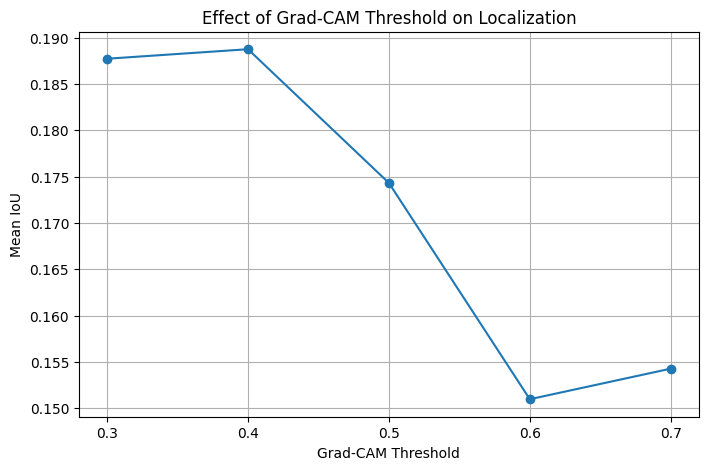

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["mean_iou"],
    marker="o"
)

plt.xlabel("Grad-CAM Threshold")
plt.ylabel("Mean IoU")
plt.title("Effect of Grad-CAM Threshold on Localization")

plt.xticks(thresholds)
plt.grid(True)

plt.show()

In [59]:
BEST_THRESHOLD = 0.4

print("Final Grad-CAM threshold:", BEST_THRESHOLD)

Final Grad-CAM threshold: 0.4


In [60]:
torch.save(
    model.state_dict(),
    "/kaggle/working/custom_cnn_pneumonia.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [61]:
# Use the same example image
final_threshold = BEST_THRESHOLD

binary_mask = (
    cam_original >= final_threshold
).astype(np.uint8) * 255

contours, _ = cv2.findContours(
    binary_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if len(contours) > 0:

    largest_contour = max(
        contours,
        key=cv2.contourArea
    )

    final_x, final_y, final_w, final_h = cv2.boundingRect(
        largest_contour
    )

    print("Final threshold:", final_threshold)
    print(
        "Final predicted box:",
        final_x,
        final_y,
        final_w,
        final_h
    )

else:
    final_x = final_y = final_w = final_h = None
    print("No bounding box detected.")

Final threshold: 0.4
Final predicted box: 145 319 349 510


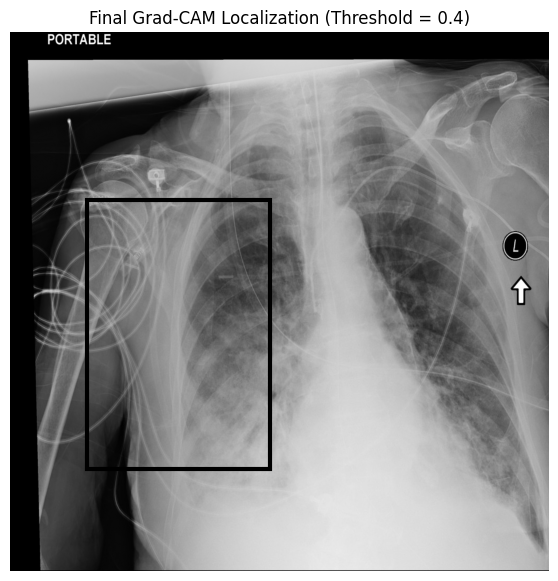

In [62]:
plt.figure(figsize=(7, 7))

plt.imshow(original_image, cmap="gray")

if final_x is not None:

    rectangle = plt.Rectangle(
        (final_x, final_y),
        final_w,
        final_h,
        fill=False,
        linewidth=3
    )

    plt.gca().add_patch(rectangle)

plt.title(
    f"Final Grad-CAM Localization "
    f"(Threshold = {final_threshold})"
)

plt.axis("off")
plt.show()

## Final Results

The final model performance is summarized using classification metrics and Grad-CAM localization performance. The Grad-CAM threshold that produced the highest mean IoU was selected as the final localization threshold.

In [66]:
# Recalculate classification metrics from the test predictions
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_prob)

final_results = {
    "Test Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc,
    "Localization Cases": int(best_row["cases"]),
    "Localization Mean IoU": float(best_row["mean_iou"]),
    "Localization Median IoU": float(best_row["median_iou"]),
    "Best IoU": float(best_row["best_iou"]),
    "Worst IoU": float(best_row["worst_iou"]),
    "Best Grad-CAM Threshold": float(best_row["threshold"]),
}

final_results_df = pd.DataFrame([final_results])

display(final_results_df)

final_results_df.to_csv(
    "/kaggle/working/final_results.csv",
    index=False
)

,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC,Localization Cases,Localization Mean IoU,Localization Median IoU,Best IoU,Worst IoU,Best Grad-CAM Threshold
0,0.786667,0.76875,0.82,0.793548,0.820711,16,0.188753,0.121795,0.486521,0.017819,0.4


In [64]:
final_results_df.to_csv(
    "/kaggle/working/final_results.csv",
    index=False
)

print("Final results saved!")

Final results saved!


## Conclusion

A custom convolutional neural network was successfully trained from scratch for binary classification of chest X-ray images into Normal and Lung Opacity classes.

The model achieved 78.67% test accuracy and a ROC-AUC of 82.07%. Grad-CAM provided weakly supervised localization of opacity regions without requiring a separate localization model.

A threshold experiment was performed using Grad-CAM, and a threshold of 0.4 produced the highest mean IoU of approximately 0.1888 on the evaluated localization cases.

The results demonstrate that a custom CNN can perform both classification and weakly supervised localization using only image-level classification training. However, the localization results are preliminary because the experiment used a limited subset of the dataset and a small number of localization cases.

## Limitations and Future Work

The current implementation uses a subset of 2,000 images and evaluates localization on a limited set of test cases. Future work can use the complete dataset, increase the number of localization samples, improve the CNN architecture, and investigate more robust methods for generating and evaluating localization maps.